# SARIMA Baseline — JalVaani
**Model:** SARIMA(1,1,1)(1,1,0)[12] — one model per district, univariate GWL only  
**Purpose:** Statistical floor — shows what pure time-series statistics achieves with *no* environmental features  
**Split:** Train 2023-01 → 2024-09 · Val 2024-10 → 2025-01 · Test 2025-02 → 2025-04  
**Note:** Monthly aggregation is used because daily SARIMA with seasonal period=365 is computationally intractable

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from tqdm.notebook import tqdm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import display

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11

MASTER    = Path('../../Data Preprocessing/clean datasets/master_dataset.csv')
OUT_DIR   = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / 'plots').mkdir(exist_ok=True)
TRAIN_END = '2024-09-30'
VAL_END   = '2025-01-31'
ORDER          = (1, 1, 1)
SEASONAL_ORDER = (1, 1, 0, 12)
SPARSE_THRESH  = 0.40

print('Libraries loaded ✓')

## 1. Load & Inspect Data

In [2]:
df = pd.read_csv(MASTER, parse_dates=['date'])
print(f'Rows      : {len(df):,}')
print(f'Districts : {df["district"].nunique()}')
print(f'Date range: {df["date"].min().date()} → {df["date"].max().date()}')
print()
display(df[['district','date','gwl_mean','gwl_min','gwl_max','station_count']].head(8))

Rows      : 16,785
Districts : 24
Date range: 2023-03-02 → 2025-04-22



,district,date,gwl_mean,gwl_min,gwl_max,station_count
0,Akola,2023-04-06,-0.88,-0.88,-0.88,1.0
1,Akola,2023-04-07,-0.88,-0.88,-0.88,1.0
2,Akola,2023-04-08,-0.88,-0.88,-0.88,1.0
3,Akola,2023-04-09,-0.88,-0.88,-0.88,1.0
4,Akola,2023-04-10,-0.88,-0.88,-0.88,1.0
5,Akola,2023-04-11,-0.88,-0.88,-0.88,1.0
6,Akola,2023-04-12,-0.88,-0.88,-0.88,1.0
7,Akola,2023-04-13,-0.88,-0.88,-0.88,1.0


In [3]:
# GWL coverage per district
coverage = (
    df.groupby('district')['gwl_mean']
    .agg(total='count', missing=lambda x: x.isna().sum())
)
coverage['missing_pct'] = (coverage['missing'] / coverage['total'] * 100).round(1)
coverage['status']      = coverage['missing_pct'].apply(
    lambda p: '✅ OK' if p < 10 else ('⚠️ GAPS' if p < 40 else '❌ SPARSE')
)
print('District GWL Coverage:')
display(coverage.sort_values('missing_pct', ascending=False))

District GWL Coverage:


,total,missing,missing_pct,status
district,,,,
Akola,748,0,0.0,✅ OK
Amravati,771,0,0.0,✅ OK
Washim,749,0,0.0,✅ OK
Wardha,761,0,0.0,✅ OK
Thane,750,0,0.0,✅ OK
Solapur,730,0,0.0,✅ OK
Satara,642,0,0.0,✅ OK
Ratnagiri,742,0,0.0,✅ OK
Raigad,729,0,0.0,✅ OK


## 2. Monthly Aggregation + Train/Val/Test Split

In [4]:
df['year_month'] = df['date'].dt.to_period('M')
monthly = (
    df.groupby(['district','year_month'])['gwl_mean']
    .mean()
    .reset_index()
)
monthly['date'] = monthly['year_month'].dt.to_timestamp()
monthly = monthly.sort_values(['district','date'])

print(f'Monthly rows : {len(monthly):,}')
print(f'Districts    : {monthly["district"].nunique()}')
print(f'Months       : {monthly["date"].min().strftime("%Y-%m")} → {monthly["date"].max().strftime("%Y-%m")}')
print()
display(monthly.head(6))

Monthly rows : 572
Districts    : 24
Months       : 2023-03 → 2025-04



,district,year_month,gwl_mean,date
0,Akola,2023-04,-0.914533,2023-04-01
1,Akola,2023-05,-2.974180,2023-05-01
2,Akola,2023-06,-3.418775,2023-06-01
3,Akola,2023-07,-3.552548,2023-07-01
4,Akola,2023-08,-2.894581,2023-08-01
5,Akola,2023-09,-3.250522,2023-09-01


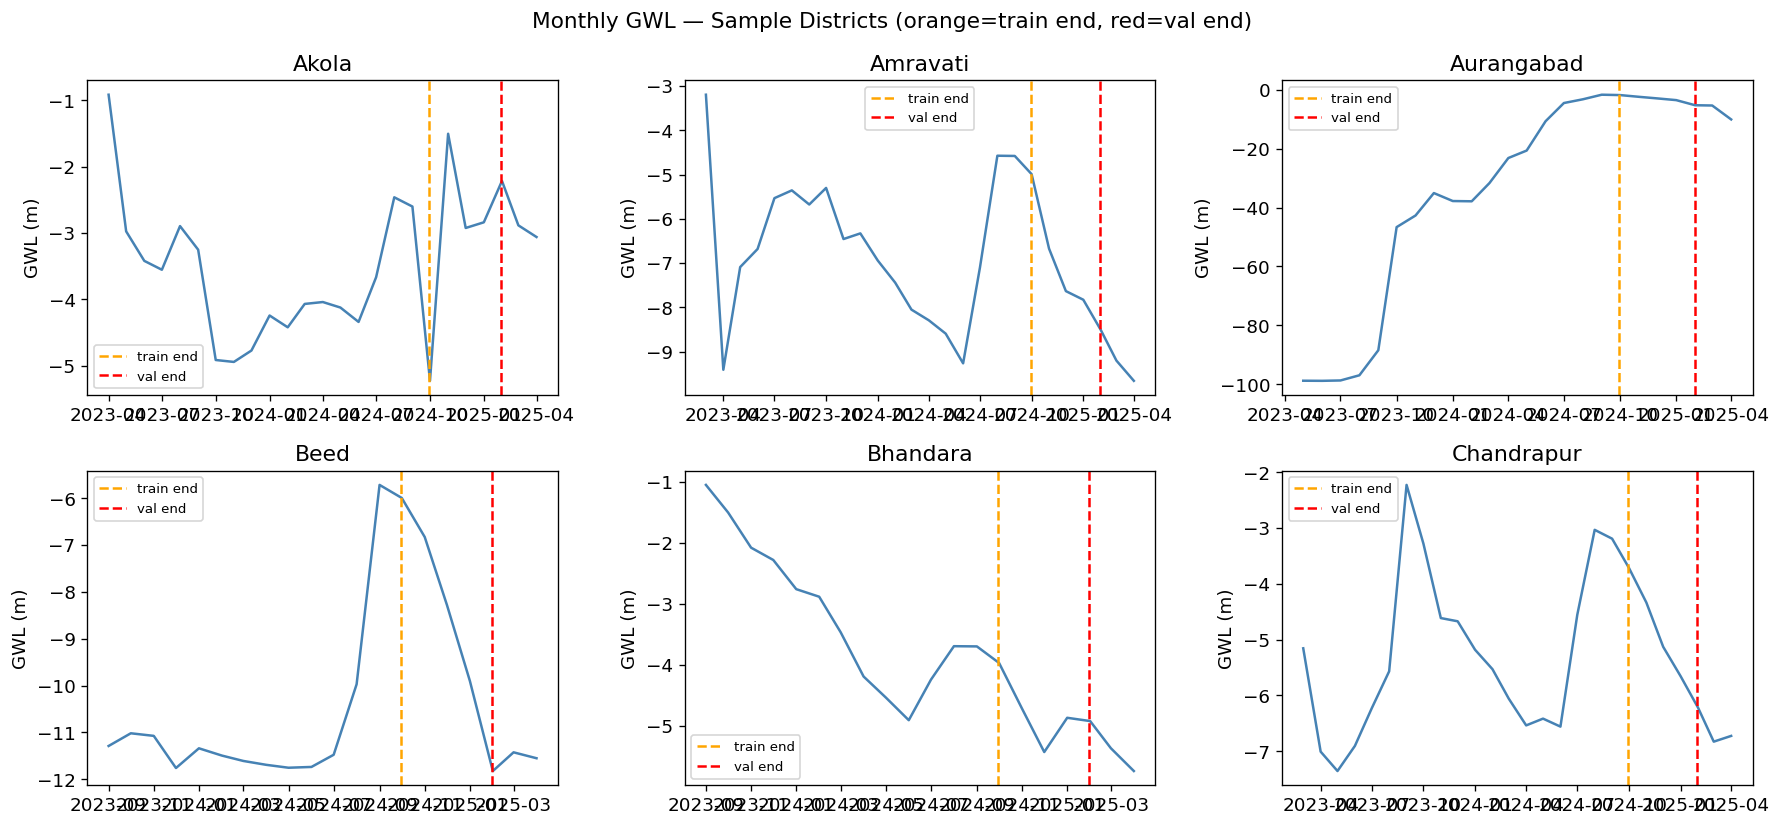

In [5]:
# Visualise monthly GWL for a few districts
sample_districts = monthly['district'].unique()[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=False)
axes = axes.flatten()
for i, dist in enumerate(sample_districts):
    grp = monthly[monthly['district'] == dist].set_index('date')['gwl_mean']
    axes[i].plot(grp.index, grp.values, color='steelblue', linewidth=1.5)
    axes[i].axvline(pd.Timestamp(TRAIN_END), color='orange', linestyle='--', label='train end')
    axes[i].axvline(pd.Timestamp(VAL_END),   color='red',    linestyle='--', label='val end')
    axes[i].set_title(dist)
    axes[i].set_ylabel('GWL (m)')
    axes[i].legend(fontsize=8)
plt.suptitle('Monthly GWL — Sample Districts (orange=train end, red=val end)', fontsize=13)
plt.tight_layout()
plt.show()

## 3. Fit SARIMA per District

In [6]:
def rmse(a, p): return np.sqrt(np.mean((np.array(a) - np.array(p))**2))
def mae(a, p):  return np.mean(np.abs(np.array(a) - np.array(p)))
def mape(a, p):
    a, p = np.array(a), np.array(p)
    mask = a != 0
    return np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100

all_preds = []
metrics   = []
skipped   = []
districts = sorted(monthly['district'].unique())

print(f'Fitting SARIMA{ORDER} × seasonal{SEASONAL_ORDER} for {len(districts)} districts ...')
print(f'(Rolling one-step-ahead forecast — this takes a few minutes per district)\n')

for dist in tqdm(districts, desc='Districts'):
    grp = monthly[monthly['district'] == dist].set_index('date')['gwl_mean']

    # Check sparsity
    miss = df[df['district']==dist]['gwl_mean'].isna().mean()
    if miss >= SPARSE_THRESH:
        print(f'  [SKIP] {dist:<22} {miss:.0%} missing (SPARSE)')
        skipped.append(dist)
        continue

    train = grp[grp.index <= TRAIN_END]
    val   = grp[(grp.index > TRAIN_END) & (grp.index <= VAL_END)]
    test  = grp[grp.index > VAL_END]

    if len(train) < 12:
        print(f'  [SKIP] {dist:<22} only {len(train)} training months')
        skipped.append(dist)
        continue

    try:
        # Rolling one-step-ahead for val
        history    = list(train)
        val_preds  = []
        for step in range(len(val)):
            m = SARIMAX(history, order=ORDER, seasonal_order=SEASONAL_ORDER,
                        enforce_stationarity=False, enforce_invertibility=False)
            r = m.fit(disp=False)
            val_preds.append(r.forecast(steps=1)[0])
            history.append(val.iloc[step])

        # Rolling one-step-ahead for test
        history2   = list(train) + list(val)
        test_preds = []
        for step in range(len(test)):
            m = SARIMAX(history2, order=ORDER, seasonal_order=SEASONAL_ORDER,
                        enforce_stationarity=False, enforce_invertibility=False)
            r = m.fit(disp=False)
            test_preds.append(r.forecast(steps=1)[0])
            history2.append(test.iloc[step])

        v_rmse = rmse(val.values,  val_preds)
        t_rmse = rmse(test.values, test_preds)
        print(f'  {dist:<22}  val RMSE={v_rmse:.3f}m   test RMSE={t_rmse:.3f}m')

        metrics.append(dict(
            district=dist,
            val_rmse=round(v_rmse,4),  val_mae=round(mae(val.values,val_preds),4),
            val_mape=round(mape(val.values,val_preds),2),
            test_rmse=round(t_rmse,4), test_mae=round(mae(test.values,test_preds),4),
            test_mape=round(mape(test.values,test_preds),2),
        ))

        for i, (a,p) in enumerate(zip(list(val.values)+list(test.values),
                                      list(val_preds)+list(test_preds))):
            sp = 'val' if i < len(val) else 'test'
            dt = (list(val.index)+list(test.index))[i]
            all_preds.append(dict(district=dist, date=dt, gwl_actual=a, gwl_predicted=p, split=sp))

    except Exception as e:
        print(f'  [FAIL] {dist:<22} {e}')
        skipped.append(dist)

print(f'\nDone. Fitted: {len(metrics)}  Skipped: {len(skipped)}')

Fitting SARIMA(1, 1, 1) × seasonal(1, 1, 0, 12) for 24 districts ...
(Rolling one-step-ahead forecast — this takes a few minutes per district)



Districts:   0%|          | 0/24 [00:00<?, ?it/s]

  Akola                   val RMSE=3.763m   test RMSE=0.642m
  Amravati                val RMSE=0.726m   test RMSE=0.418m
  Aurangabad              val RMSE=137.695m   test RMSE=7.598m
  [FAIL] Beed                   too many indices for array: array is 0-dimensional, but 1 were indexed
  [FAIL] Bhandara               too many indices for array: array is 0-dimensional, but 1 were indexed
  Chandrapur              val RMSE=1.376m   test RMSE=0.358m
  [FAIL] Dhule                  too many indices for array: array is 0-dimensional, but 1 were indexed
  [FAIL] Gadchiroli             too many indices for array: array is 0-dimensional, but 1 were indexed
  Gondia                  val RMSE=4.508m   test RMSE=3.068m
  Jalgaon                 val RMSE=369.585m   test RMSE=11.360m
  [FAIL] Kolhapur               too many indices for array: array is 0-dimensional, but 1 were indexed
  Nagpur                  val RMSE=6.268m   test RMSE=0.296m
  Nanded                  val RMSE=23.923m   test RMS

## 4. Results

In [7]:
metrics_df = pd.DataFrame(metrics)
print('=== SARIMA — Per-District Results ===')
display(metrics_df.style.background_gradient(subset=['test_rmse'], cmap='YlOrRd'))
print()
print('=== Aggregate Mean (across all fitted districts) ===')
agg = metrics_df[['val_rmse','val_mae','val_mape','test_rmse','test_mae','test_mape']].mean().round(4)
display(agg.to_frame('mean').T)

=== SARIMA — Per-District Results ===


,district,val_rmse,val_mae,val_mape,test_rmse,test_mae,test_mape
0,Akola,3.763400,3.206400,107.600000,0.641500,0.639400,23.710000
1,Amravati,0.726300,0.674100,9.720000,0.417500,0.382900,4.280000
2,Aurangabad,137.695100,94.549400,4154.120000,7.598300,6.548300,89.800000
3,Chandrapur,1.376500,1.071700,26.200000,0.357600,0.316400,4.790000
4,Gondia,4.508200,3.777700,34.960000,3.068500,2.721900,22.300000
5,Jalgaon,369.584900,186.675900,1870.110000,11.359900,9.382500,52.220000
6,Nagpur,6.268100,3.423600,96.870000,0.295900,0.271800,4.380000
7,Nanded,23.922800,12.733900,309.370000,0.174500,0.171200,1.350000
8,Nandurbar,18.011200,9.573000,62.490000,4.823100,4.690500,13.350000
9,Nashik,6.550900,5.355100,86.230000,3.344100,2.670700,18.250000



=== Aggregate Mean (across all fitted districts) ===


,val_rmse,val_mae,val_mape,test_rmse,test_mae,test_mape
mean,32.0595,18.2621,376.3379,2.1672,1.8647,16.2411


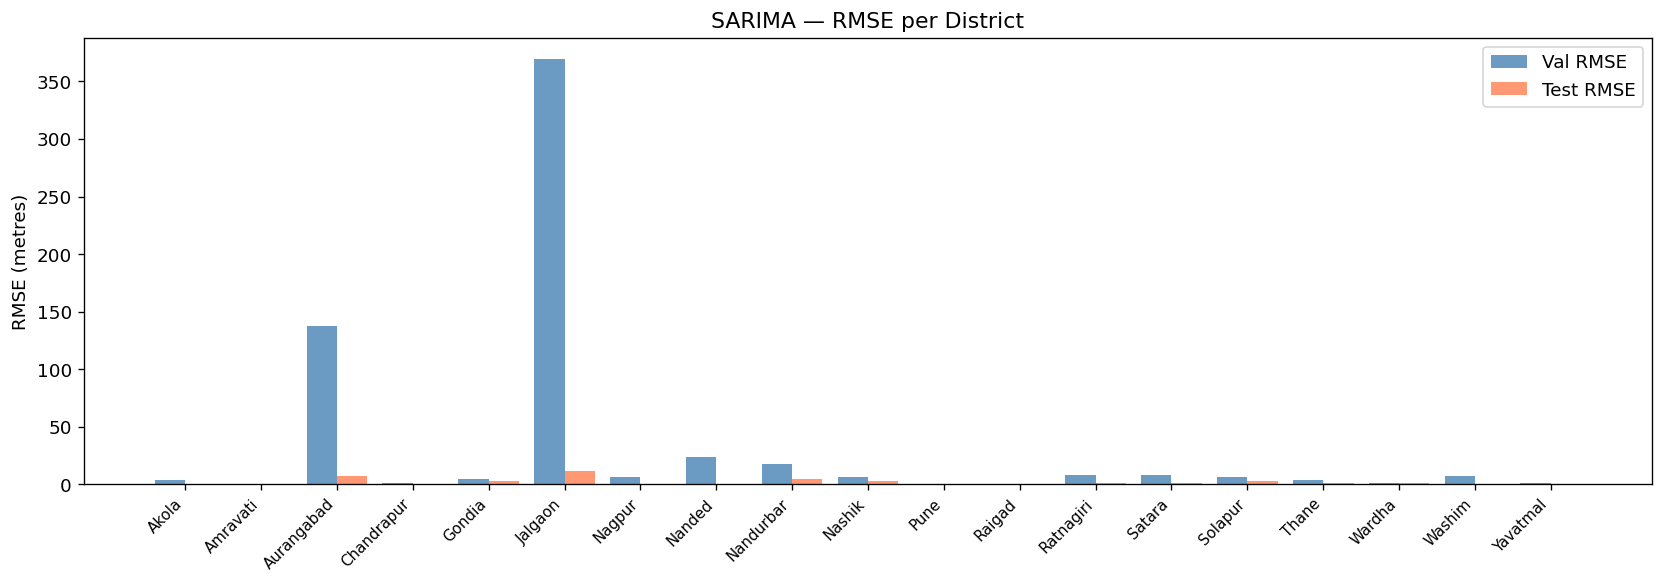

In [8]:
# RMSE bar chart per district
fig, ax = plt.subplots(figsize=(14, 5))
x = range(len(metrics_df))
ax.bar([i - 0.2 for i in x], metrics_df['val_rmse'],  width=0.4, label='Val RMSE',  color='steelblue', alpha=0.8)
ax.bar([i + 0.2 for i in x], metrics_df['test_rmse'], width=0.4, label='Test RMSE', color='coral',     alpha=0.8)
ax.set_xticks(list(x))
ax.set_xticklabels(metrics_df['district'], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('RMSE (metres)')
ax.set_title('SARIMA — RMSE per District')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'sarima_rmse_per_district.png', dpi=150)
plt.show()

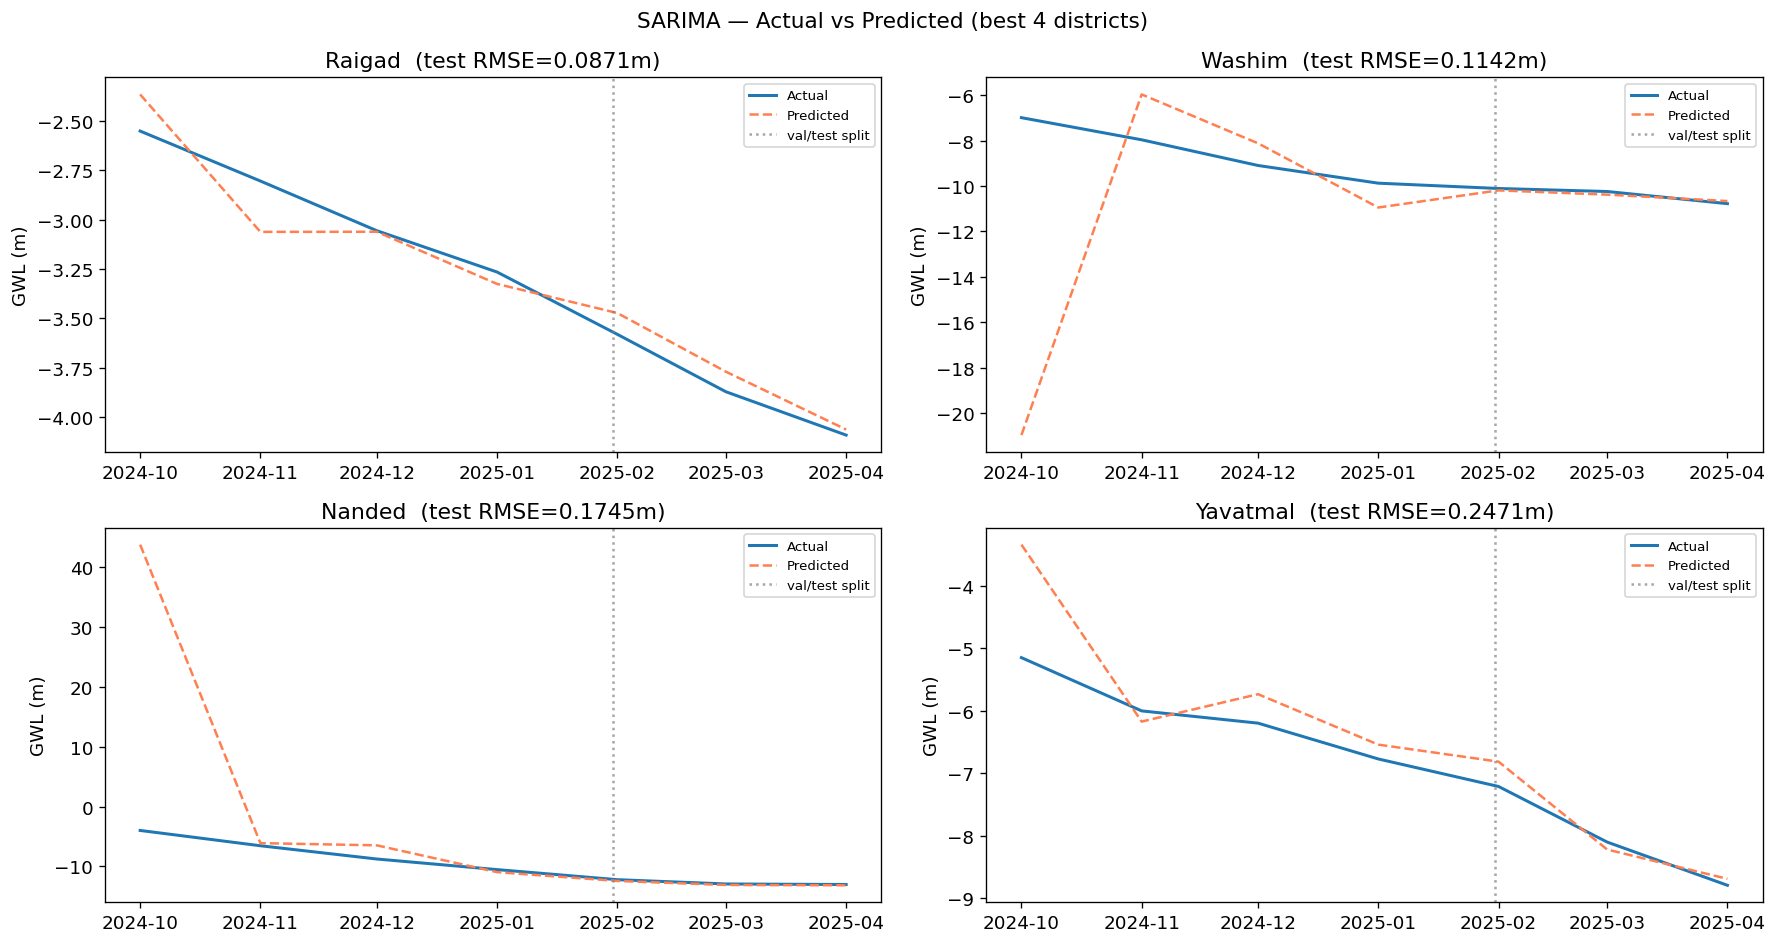

In [9]:
# Actual vs predicted plots for up to 4 districts
preds_df = pd.DataFrame(all_preds)
plot_dists = metrics_df.nsmallest(4, 'test_rmse')['district'].tolist()

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()
for i, dist in enumerate(plot_dists):
    sub = preds_df[preds_df['district']==dist].sort_values('date')
    axes[i].plot(sub['date'], sub['gwl_actual'],   label='Actual',    linewidth=1.8)
    axes[i].plot(sub['date'], sub['gwl_predicted'],label='Predicted', linewidth=1.5, linestyle='--', color='coral')
    axes[i].axvline(pd.Timestamp(VAL_END), color='gray', linestyle=':', alpha=0.7, label='val/test split')
    rmse_val = metrics_df[metrics_df['district']==dist]['test_rmse'].values[0]
    axes[i].set_title(f'{dist}  (test RMSE={rmse_val}m)')
    axes[i].set_ylabel('GWL (m)')
    axes[i].legend(fontsize=8)
plt.suptitle('SARIMA — Actual vs Predicted (best 4 districts)', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'sarima_actual_vs_pred.png', dpi=150)
plt.show()

## 5. Save Outputs

In [10]:
preds_df.to_csv(OUT_DIR / 'arima_predictions.csv', index=False)
metrics_df.to_csv(OUT_DIR / 'arima_metrics.csv', index=False)
print('Saved: arima_predictions.csv')
print('Saved: arima_metrics.csv')
print('Saved: sarima_rmse_per_district.png')
print('Saved: sarima_actual_vs_pred.png')
print(f'\nAggregate test RMSE : {metrics_df["test_rmse"].mean():.4f} m')
print(f'Aggregate test MAE  : {metrics_df["test_mae"].mean():.4f} m')
print(f'Aggregate test MAPE : {metrics_df["test_mape"].mean():.2f} %')

Saved: arima_predictions.csv
Saved: arima_metrics.csv
Saved: sarima_rmse_per_district.png
Saved: sarima_actual_vs_pred.png

Aggregate test RMSE : 2.1672 m
Aggregate test MAE  : 1.8647 m
Aggregate test MAPE : 16.24 %
